# AI-Enhanced Intrusion Detection System

## Multi-class Model Training using CICIDS2017

---

### 📌 Objective

This notebook develops a **multi-class machine learning model** for network intrusion detection using the CICIDS2017 dataset.

The model classifies network traffic into multiple attack categories and normal traffic, enabling more detailed and realistic threat analysis.

---

### ⚙️ Pipeline Overview

1. Load CICIDS2017 dataset
2. Data cleaning & preprocessing
3. Feature selection
4. Multi-class label encoding
5. Feature scaling
6. Model training (Random Forest)
7. Model evaluation
8. Model export for deployment

---

### 🎯 Goal

Build an intelligent intrusion detection system capable of:

* Identifying different types of attacks
* Providing detailed classification beyond simple detection
* Supporting real-time risk analysis in later stages

---

### 🧠 Key Idea

Instead of treating all malicious traffic as a single category, the system distinguishes between different attack behaviors such as:

* DoS
* Port Scanning
* Brute Force
* Web Attacks

This allows the system to generate more meaningful security insights.


In [1]:
import pandas as pd
import glob

base_path = "/kaggle/input/datasets/rynq18/file-zip/MachineLearningCSV/MachineLearningCVE"

csv_files = glob.glob(base_path + "/*.csv")

print("Number of files:", len(csv_files))

df_list = []

for file in csv_files:
    temp = pd.read_csv(file, low_memory=False)
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

print("Final shape:", df.shape)

df.head()

Number of files: 8
Final shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [2]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [3]:
label_counts = df["Label"].value_counts()

print(label_counts)
print()
print("Number of classes:", df["Label"].nunique())

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Number of classes: 15


## Attack Label Consolidation

The original CICIDS2017 dataset contains multiple fine-grained attack labels.
However, these labels are highly imbalanced and fragmented, which can negatively impact model performance.

To address this, attack types were grouped into higher-level categories based on their behavior and characteristics.

---

### Grouped Attack Categories

* **BENIGN** → Normal traffic
* **DoS** → Includes DoS Hulk, DDoS, Slowloris, Slowhttptest, GoldenEye
* **PortScan** → Network scanning activity
* **Brute Force** → Includes FTP and SSH brute force attacks
* **Web Attack** → Includes XSS, SQL Injection, and Web Brute Force
* **Rare Attack** → Includes Infiltration and Heartbleed

---

### Rationale

This grouping approach:

* Reduces class imbalance
* Improves model generalization
* Preserves meaningful attack distinctions
* Enables more stable multi-class learning

---

### Resulting Distribution

The dataset now contains six balanced and interpretable classes suitable for machine learning.


In [4]:
attack_map = {
    "BENIGN": "BENIGN",

    "DoS Hulk": "DoS",
    "DoS GoldenEye": "DoS",
    "DoS Slowloris": "DoS",
    "DoS slowloris": "DoS",
    "DoS Slowhttptest": "DoS",
    "DDoS": "DoS",

    "PortScan": "PortScan",

    "FTP-Patator": "Brute Force",
    "SSH-Patator": "Brute Force",

    "Web Attack - Brute Force": "Web Attack",
    "Web Attack - XSS": "Web Attack",
    "Web Attack - Sql Injection": "Web Attack",
    "Web Attack � Brute Force": "Web Attack",
    "Web Attack � XSS": "Web Attack",
    "Web Attack � Sql Injection": "Web Attack",

    "Infiltration": "Rare Attack",
    "Heartbleed": "Rare Attack",
    "Bot": "Rare Attack"
}

In [5]:
df["Label"] = df["Label"].str.strip()
df["Label"] = df["Label"].str.replace("–", "-", regex=False)

In [6]:
df["Attack_Type"] = df["Label"].map(attack_map)

print(df["Attack_Type"].value_counts())
print()
print("Missing:", df["Attack_Type"].isna().sum())

Attack_Type
BENIGN         2273097
DoS             380688
PortScan        158930
Brute Force      13835
Web Attack        2180
Rare Attack       2013
Name: count, dtype: int64

Missing: 0


In [7]:
missing_labels = df[df["Attack_Type"].isna()]["Label"].value_counts()
print(missing_labels)

Series([], Name: count, dtype: int64)


In [8]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["target"] = le.fit_transform(df["Attack_Type"])

print(dict(zip(le.classes_, le.transform(le.classes_))))
print()
print(df[["Label", "Attack_Type", "target"]].head(10))

{'BENIGN': np.int64(0), 'Brute Force': np.int64(1), 'DoS': np.int64(2), 'PortScan': np.int64(3), 'Rare Attack': np.int64(4), 'Web Attack': np.int64(5)}

    Label Attack_Type  target
0  BENIGN      BENIGN       0
1  BENIGN      BENIGN       0
2  BENIGN      BENIGN       0
3  BENIGN      BENIGN       0
4  BENIGN      BENIGN       0
5  BENIGN      BENIGN       0
6  BENIGN      BENIGN       0
7  BENIGN      BENIGN       0
8  BENIGN      BENIGN       0
9  BENIGN      BENIGN       0


In [9]:
X = df.drop(columns=["Label", "Attack_Type", "target"])
y = df["target"]

print(X.shape)
print(y.shape)

(2830743, 78)
(2830743,)


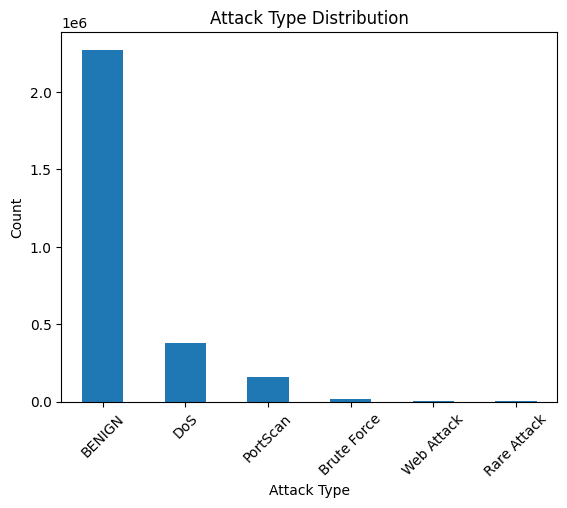

In [10]:
import matplotlib.pyplot as plt

df["Attack_Type"].value_counts().plot(kind="bar")

plt.title("Attack Type Distribution")
plt.xlabel("Attack Type")
plt.ylabel("Count")

plt.xticks(rotation=45)
plt.show()

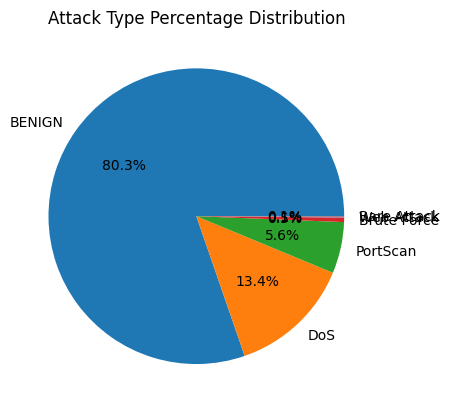

In [11]:
df["Attack_Type"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.title("Attack Type Percentage Distribution")
plt.ylabel("")
plt.show()

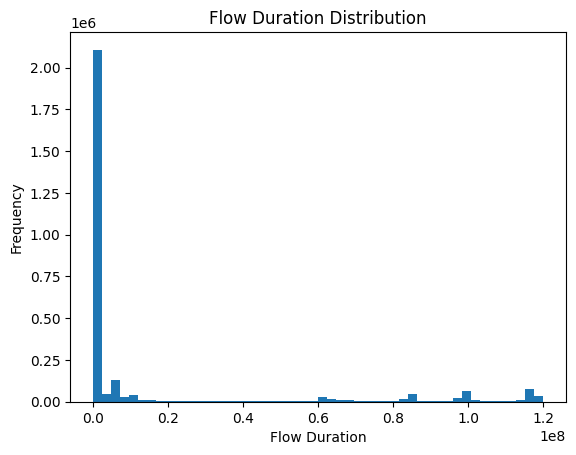

In [12]:
plt.hist(df["Flow Duration"], bins=50)

plt.title("Flow Duration Distribution")
plt.xlabel("Flow Duration")
plt.ylabel("Frequency")

plt.show()

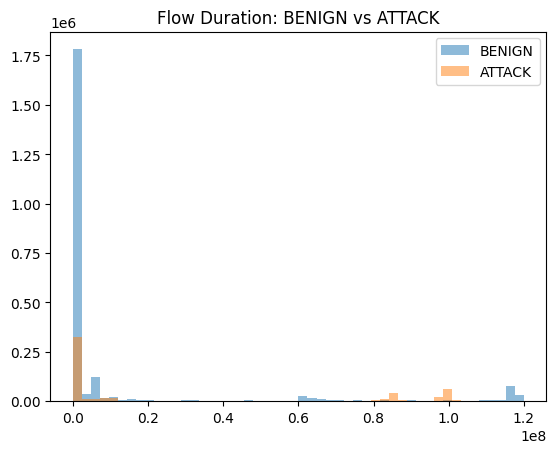

In [13]:
benign = df[df["Attack_Type"] == "BENIGN"]
attack = df[df["Attack_Type"] != "BENIGN"]

plt.hist(benign["Flow Duration"], bins=50, alpha=0.5, label="BENIGN")
plt.hist(attack["Flow Duration"], bins=50, alpha=0.5, label="ATTACK")

plt.legend()
plt.title("Flow Duration: BENIGN vs ATTACK")

plt.show()

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(2264594, 78)
(566149, 78)


In [15]:
import numpy as np

X_train = np.where(np.isfinite(X_train), X_train, 0)
X_test = np.where(np.isfinite(X_test), X_test, 0)

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [17]:
print(type(X_train))
print(X_train.shape)
print(X_test.shape)

<class 'numpy.ndarray'>
(2264594, 78)
(566149, 78)


In [18]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [19]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    454620
           1       1.00      1.00      1.00      2767
           2       1.00      1.00      1.00     76138
           3       0.99      1.00      0.99     31786
           4       0.93      0.77      0.84       402
           5       1.00      0.96      0.98       436

    accuracy                           1.00    566149
   macro avg       0.99      0.95      0.97    566149
weighted avg       1.00      1.00      1.00    566149



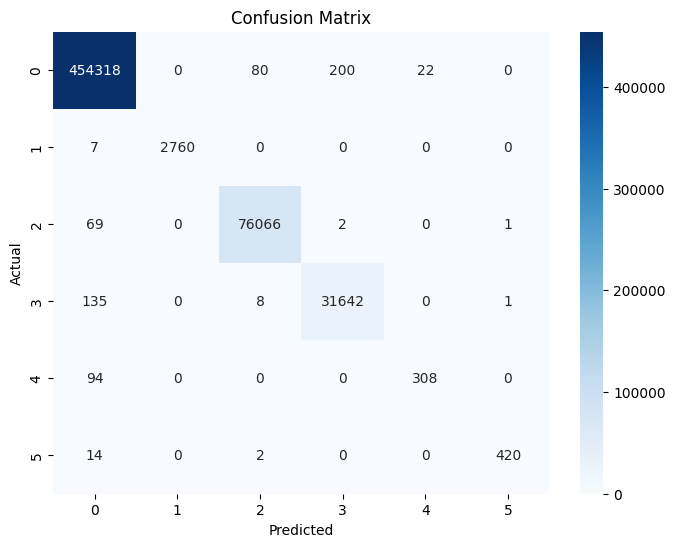

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## Model Evaluation

The model achieved near-perfect performance on the major classes such as BENIGN, DoS, and PortScan, which are well-represented in the dataset.

For smaller classes such as Rare Attack, performance is slightly lower. This is expected due to class imbalance, as these classes contain significantly fewer samples.

Overall, the model demonstrates strong generalization and effective multi-class classification performance.


In [21]:
import joblib

joblib.dump(model, "model_multiclass.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(le, "label_encoder.pkl")

['label_encoder.pkl']

In [22]:
import json

feature_columns = X.columns.tolist()

with open("feature_columns.json", "w") as f:
    json.dump(feature_columns, f)

print("saved")

saved


In [23]:
df.to_csv("/kaggle/working/final_dataset_multiclass.csv", index=False)

In [24]:
import os
print(os.listdir("/kaggle/working"))

['scaler.pkl', 'model_multiclass.pkl', 'label_encoder.pkl', 'final_dataset_multiclass.csv', 'feature_columns.json', '__notebook__.ipynb']
